### News

**Read our [Gemma 3 blog](https://unsloth.ai/blog/gemma3) for what's new in Unsloth and our [Reasoning blog](https://unsloth.ai/blog/r1-reasoning) on how to train reasoning models.**

Visit our docs for all our [model uploads](https://docs.unsloth.ai/get-started/all-our-models) and [notebooks](https://docs.unsloth.ai/get-started/unsloth-notebooks).


### Installation

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
%%capture
import os
if "COLAB_" not in "".join(os.environ.keys()):
    !pip install unsloth vllm
else:
    # [NOTE] Do the below ONLY in Colab! Use [[pip install unsloth vllm]]
    !pip install --no-deps unsloth vllm
# Install latest Hugging Face for Gemma-3!
!pip install --no-deps git+https://github.com/huggingface/transformers@v4.49.0-Gemma-3
!pip install bitsandbytes
!pip install unsloth_zoo
!pip install msgspec
!pip install blake3
!pip install gguf
!pip install networkx==2.8.8 --force-reinstall

In [3]:
#@title Colab Extra Install { display-mode: "form" }
%%capture
import os
if "COLAB_" not in "".join(os.environ.keys()):
    !pip install unsloth vllm
else:
    !pip install --no-deps unsloth vllm
    # [NOTE] Do the below ONLY in Colab! Use [[pip install unsloth vllm]]
    # Skip restarting message in Colab
    import sys, re, requests; modules = list(sys.modules.keys())
    for x in modules: sys.modules.pop(x) if "PIL" in x or "google" in x else None
    !pip install --no-deps bitsandbytes accelerate xformers==0.0.29.post3 peft trl triton cut_cross_entropy unsloth_zoo
    !pip install sentencepiece protobuf datasets huggingface_hub hf_transfer

    # vLLM requirements - vLLM breaks Colab due to reinstalling numpy
    f = requests.get("https://raw.githubusercontent.com/vllm-project/vllm/refs/heads/main/requirements/common.txt").content
    with open("vllm_requirements.txt", "wb") as file:
        file.write(re.sub(rb"(transformers|numpy|xformers)[^\n]{1,}\n", b"", f))
    !pip install -r vllm_requirements.txt

In [4]:
# Install a compatible version of Pillow to fix the _imaging import error
!pip install --upgrade --force-reinstall pillow==10.4.0

  Using cached pillow-10.4.0-cp313-cp313-manylinux_2_28_x86_64.whl.metadata (9.2 kB)
Using cached pillow-10.4.0-cp313-cp313-manylinux_2_28_x86_64.whl (4.5 MB)
  Attempting uninstall: pillow
    Found existing installation: pillow 13.0.0
    Uninstalling pillow-13.0.0:
      Successfully uninstalled pillow-13.0.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
vllm 0.34.0 requires fastsafetensors>=0.3.3, which is not installed.
vllm 0.34.0 requires flashinfer-python==0.7.3, which is not installed.
vllm 0.34.0 requires humming-kernels[cu13]==0.1.19, which is not installed.
vllm 0.34.0 requires instanttensor>=0.2.2, which is not installed.
vllm 0.34.0 requires lm-format-enforcer==0.11.3, which is not installed.
vllm 0.34.0 requires nvidia-cudnn-frontend>=1.31.0, which is not installed.
vllm 0.34.0 requires nvidia-cutlass-dsl[cu13]==4.8.0, which is not installed.
v

### Unsloth

`FastModel` supports loading nearly any model now! This includes Vision and Text models!

In [5]:
from unsloth import FastModel
import torch

fourbit_models = [
    # 4bit dynamic quants for superior accuracy and low memory use
    "unsloth/gemma-3-1b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-4b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-12b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-27b-it-unsloth-bnb-4bit",

    # Other popular models!
    "unsloth/Llama-3.1-8B",
    "unsloth/Llama-3.2-3B",
    "unsloth/Llama-3.3-70B",
    "unsloth/mistral-7b-instruct-v0.3",
    "unsloth/Phi-4",
] # More models at https://huggingface.co/unsloth

model, tokenizer = FastModel.from_pretrained(
    model_name = "unsloth/gemma-3-4b-it",
    max_seq_length = 2048, # Choose any for long context!
    load_in_4bit = True,  # 4 bit quantization to reduce memory
    load_in_8bit = False, # [NEW!] A bit more accurate, uses 2x memory
    full_finetuning = False, # [NEW!] We have full finetuning now!
    # token = "hf_...", # use one if using gated models
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1125 21:55:06.985000 6656 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1125 21:55:07.051000 6656 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1125 21:55:10.863000 6656 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1125 21:55:10.866000 6656 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1125 21:55:10.871000 6656 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.12: Fast Gemma3 patching. Transformers: 5.18.0. vLLM: 0.34.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

We now add LoRA adapters so we only need to update a small amount of parameters!

In [6]:
model = FastModel.get_peft_model(
    model,
    finetune_vision_layers     = False, # Turn off for just text!
    finetune_language_layers   = True,  # Should leave on!
    finetune_attention_modules = True,  # Attention good for GRPO
    finetune_mlp_modules       = True,  # SHould leave on always!

    r = 8,           # Larger = higher accuracy, but might overfit
    lora_alpha = 8,  # Recommended alpha == r at least
    lora_dropout = 0,
    bias = "none",
    random_state = 3407,
)

<a name="Data"></a>
### Data Prep
We now use the `Gemma-3` format for conversation style finetunes. We use [Maxime Labonne's FineTome-100k](https://huggingface.co/datasets/mlabonne/FineTome-100k) dataset in ShareGPT style. Gemma-3 renders multi turn conversations like below:

```
<bos><start_of_turn>user
Hello!<end_of_turn>
<start_of_turn>model
Hey there!<end_of_turn>
```

We use our `get_chat_template` function to get the correct chat template. We support `zephyr, chatml, mistral, llama, alpaca, vicuna, vicuna_old, phi3, llama3, phi4, qwen2.5, gemma3` and more.

In [7]:
from unsloth.chat_templates import get_chat_template
tokenizer = get_chat_template(
    tokenizer,
    chat_template = "gemma-3",
)

In [8]:
from datasets import load_dataset
dataset = load_dataset('csv',data_files="/content/drive/MyDrive/dataasilida_cleaned.csv")

Generating train split: 0 examples [00:00, ? examples/s]

In [9]:
# Print the column names of the loaded dataset to inspect its structure
print("Available columns:", dataset['train'].column_names)
# Also display the first row to inspect the content structure
dataset['train'][0]

Available columns: ['input,output', '__index_level_0__']


{'input,output': 'ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមរយៈ E-Commerce ម៉ាស៊ីនឆូតកាត (POS) ម៉ាស៊ីនអេធីអឹម (ATM) ដែលមានបិទស្លាកសញ្ញា ចេស៊ីប៊ី នៅទូទាំងប្រទេស និងពាសពេញពិភពលោក ដោយធ្វើការទូទាត់សាច់ប្រាក់ចេញពីគណនីរបស់ម្ចាស់ប័ណ្ណដែលមាននៅធនាគារ អេស៊ីលីដា។',
 '__index_level_0__': 'តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី'}

In [10]:
def formatting_prompts_func(examples):
    # '__index_level_0__' contains the user questions (input)
    # 'input,output' contains the assistant responses (output)
    instructions = examples["__index_level_0__"]
    outputs      = examples["input,output"]
    texts = []
    for instruction, output in zip(instructions, outputs):
      # Force conversion to string to prevent float/NaN from causing TemplateErrors
      instruction_str = str(instruction).strip() if (instruction is not None and not isinstance(instruction, float)) else ""
      output_str = str(output).strip() if (output is not None and not isinstance(output, float)) else ""

      # Skip completely empty dataset entries
      if not instruction_str and not output_str:
          continue

      messages = [
        {
            "role": "user", "content": instruction_str
        },
        {
            "role": "assistant", "content": output_str
        }
      ]
      text = tokenizer.apply_chat_template(messages, add_generation_prompt=False, tokenize=False)
      texts.append(text)
    return {"text": texts}

In [11]:
# We already loaded the dataset into the `dataset` variable from '/content/drive/MyDrive/dataasilida_cleaned.csv' in cell Mkq4RvEq7FQr
dataset = dataset.map(formatting_prompts_func, batched = True)

Map:   0%|          | 0/521 [00:00<?, ? examples/s]

In [12]:
dataset['train']['text'][0]

'<bos><start_of_turn>user\nតើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី<end_of_turn>\n<start_of_turn>model\nប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមរយៈ E-Commerce ម៉ាស៊ីនឆូតកាត (POS) ម៉ាស៊ីនអេធីអឹម (ATM) ដែលមានបិទស្លាកសញ្ញា ចេស៊ីប៊ី នៅទូទាំងប្រទេស និងពាសពេញពិភពលោក ដោយធ្វើការទូទាត់សាច់ប្រាក់ចេញពីគណនីរបស់ម្ចាស់ប័ណ្ណដែលមាននៅធនាគារ អេស៊ីលីដា។<end_of_turn>\n'

Let's see how row 100 looks like!

In [14]:
dataset['train']['__index_level_0__'][0]

'តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី'

In [15]:
dataset['train']['__index_level_0__'][0]

'តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី'

Let's see how the chat template did! Notice `Gemma-3` default adds a `<bos>`!

In [16]:
dataset['train']['input,output'][0]

'ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមរយៈ E-Commerce ម៉ាស៊ីនឆូតកាត (POS) ម៉ាស៊ីនអេធីអឹម (ATM) ដែលមានបិទស្លាកសញ្ញា ចេស៊ីប៊ី នៅទូទាំងប្រទេស និងពាសពេញពិភពលោក ដោយធ្វើការទូទាត់សាច់ប្រាក់ចេញពីគណនីរបស់ម្ចាស់ប័ណ្ណដែលមាននៅធនាគារ អេស៊ីលីដា។'

<a name="Train"></a>
### Train the model
Now let's use Huggingface TRL's `SFTTrainer`! More docs here: [TRL SFT docs](https://huggingface.co/docs/trl/sft_trainer). We do 60 steps to speed things up, but you can set `num_train_epochs=1` for a full run, and turn off `max_steps=None`.

In [17]:
from trl import SFTTrainer, SFTConfig

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = dataset['train'],
    eval_dataset = None,
    args = SFTConfig(
        dataset_text_field = "text",
        per_device_train_batch_size = 2,
        gradient_accumulation_steps = 4,
        warmup_steps = 5,
        max_steps = 60,
        learning_rate = 2e-4,
        logging_steps = 1,
        optim = "adamw_8bit",
        weight_decay = 0.01,
        lr_scheduler_type = "linear",
        seed = 3407,
        report_to = "none",
    ),
)

`torch_dtype` is deprecated! Use `dtype` instead!


Unsloth: Switching to float32 training since model cannot work with float16
Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/521 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


In [18]:
from trl import SFTTrainer, SFTConfig
from unsloth import is_bfloat16_supported

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = dataset['train'],
    eval_dataset = None,
    args = SFTConfig(
        dataset_text_field = "text",
        per_device_train_batch_size = 2,
        gradient_accumulation_steps = 4,
        warmup_steps = 5,
        max_steps = 60,
        learning_rate = 2e-4,
        logging_steps = 1,
        optim = "adamw_8bit",
        weight_decay = 0.01,
        lr_scheduler_type = "linear",
        seed = 3407,
        fp16 = not is_bfloat16_supported(),
        bf16 = is_bfloat16_supported(),
        output_dir = "outputs",
        report_to = "none",
    ),
)

Unsloth: Switching to float32 training since model cannot work with float16
Unsloth: We found double BOS tokens - we shall remove one automatically.
🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


We also use Unsloth's `train_on_completions` method to only train on the assistant outputs and ignore the loss on the user's inputs. This helps increase accuracy of finetunes!

In [19]:
from unsloth.chat_templates import train_on_responses_only
trainer = train_on_responses_only(
    trainer,
    instruction_part = "<start_of_turn>user\n",
    response_part = "<start_of_turn>model\n",
)

Map:   0%|          | 0/521 [00:00<?, ? examples/s]

Let's verify masking the instruction part is done! Let's print the 100th row again:

In [20]:
tokenizer.decode(trainer.train_dataset[100]["input_ids"])

'<bos><start_of_turn>user\nតើត្រូវមានលក្ខខណ្ឌតម្រូវអ្វីខ្លះ សម្រាប់ការស្នើសុំបង្កើតប័ណ្ណនិម្មិតតាមសេវាអេស៊ីលីដាម៉ូបាល<end_of_turn>\n<start_of_turn>model\nអតិថិជនត្រូវមានគណនីប្រភព (គណនីធនាគារ) ជាប្រាក់ដុល្លារអាមេរិក ដែលបានភ្ជាប់ជាមួយសេវាអេ-ស៊ីលីដាម៉ូបាល។ \\n ត្រូវបម្រុងសមតុល្យគណនីឲ្យបានគ្រប់គ្រាន់ រាល់ពេលបង្កើតប័ណ្ណ និងពេលទូទាត់ថ្លៃទំនិញ-សេវាកម្ម ។<end_of_turn>\n'

Now let's print the masked out example - you should see only the answer is present:

In [21]:
tokenizer.decode([tokenizer.pad_token_id if x == -100 else x for x in trainer.train_dataset[100]["labels"]]).replace(tokenizer.pad_token, " ")

'                                                  អតិថិជនត្រូវមានគណនីប្រភព (គណនីធនាគារ) ជាប្រាក់ដុល្លារអាមេរិក ដែលបានភ្ជាប់ជាមួយសេវាអេ-ស៊ីលីដាម៉ូបាល។ \\n ត្រូវបម្រុងសមតុល្យគណនីឲ្យបានគ្រប់គ្រាន់ រាល់ពេលបង្កើតប័ណ្ណ និងពេលទូទាត់ថ្លៃទំនិញ-សេវាកម្ម ។<end_of_turn> '

In [22]:
# @title Show current memory stats
gpu_stats = torch.cuda.get_device_properties(0)
start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
max_memory = round(gpu_stats.total_memory / 1024 / 1024 / 1024, 3)
print(f"GPU = {gpu_stats.name}. Max memory = {max_memory} GB.")
print(f"{start_gpu_memory} GB of memory reserved.")

GPU = Tesla T4. Max memory = 14.563 GB.
4.518 GB of memory reserved.


Let's train the model! To resume a training run, set `trainer.train(resume_from_checkpoint = True)`

In [23]:
trainer_stats = trainer.train()

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 106}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 521 | Num Epochs = 1 | Total steps = 60
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 14,901,248 of 4,314,980,720 (0.35% trained)


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss
1,3.279120
2,2.871105
3,3.557190
4,3.019154
5,2.831603
6,3.018806
7,2.444665
8,1.932890
9,1.888523
10,1.819391


Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-60/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-60.


### 📚 Learning Objective 1: Course Summary & Core Concepts

#### 1. Large Language Model (LLM) Fine-Tuning Workflow
Fine-tuning is the process of taking a pre-trained base model (which has general language capabilities) and training it further on a domain-specific dataset. This teaches the model specialized behaviors, formats, or knowledge structures.

#### 2. Gemma 3
Google's Gemma 3 is a highly efficient open-weights model family. In this notebook, we use the `gemma-3-4b-it` model which includes multi-modal and advanced reasoning capabilities.

#### 3. Parameter-Efficient Fine-Tuning (PEFT) & Low-Rank Adaptation (LoRA)
* **Full Fine-Tuning:** Updates all billions of parameters in the model. This is extremely memory-intensive and prone to catastrophic forgetting.
* **PEFT:** Methods that reduce the number of trainable parameters, saving memory and compute.
* **LoRA:** A specific PEFT method that freezes the original model weights and injects trainable rank-decomposition matrices (using hyperparameters $r$ and $\alpha$) into the attention and MLP layers. This allows us to train less than 1% of the original parameters while achieving comparable accuracy.

### ⚙️ Learning Objective 2: Notebook Configuration & Hyperparameters

To optimize your training run, you can adjust these primary hyperparameters inside your `TrainingArguments` (or `SFTConfig`):

| Hyperparameter | Role | Impact |
| :--- | :--- | :--- |
| `learning_rate` | Controls step size during gradient updates | Too high causes training instability; too low makes learning extremely slow. |
| `per_device_train_batch_size` | Number of samples processed simultaneously per GPU | Larger sizes speed up training but consume more GPU VRAM. |
| `gradient_accumulation_steps` | Accumulates gradients over multiple steps before updating weights | Simulates a larger batch size without requiring more GPU VRAM. |
| `max_steps` / `num_train_epochs` | Duration of the training process | Too few steps lead to underfitting; too many lead to overfitting. |
| `optim` | Optimization algorithm (e.g., `adamw_8bit`) | Using 8-bit optimizers drastically lowers memory footprint. |

### 📈 Learning Objective 3: Loss Analysis (Overfitting vs. Underfitting)

During training, monitoring the loss metrics is vital to understand model performance:

* **Underfitting:** Both training loss and validation loss remain high. The model has not learned the target patterns. Solution: Increase `max_steps`/epochs, raise the learning rate, or increase the LoRA rank $r$.
* **Overfitting:** Training loss continues to decline, but validation loss starts to increase or plateaus while training loss drops to near zero. The model is memorizing the training data. Solution: Introduce dropout, decrease LoRA rank $r$, collect more diverse data, or use early stopping.

### 🔬 Learning Objective 4: Practical Experimentation

Let's set up a template to run a comparative experiment. You can load a different instruction dataset (such as an English Alpaca dataset) to fine-tune the model and observe the behavioral change.

In [24]:
# Optional Experiment: Run this cell to load a different public dataset
# and contrast the model's behavior with the Khmer instructions above.
from datasets import load_dataset

try:
    # Load a small sample of the standard Alpaca dataset
    experiment_dataset = load_dataset("tatsu-lab/alpaca", split="train[:500]")
    print("Experiment dataset loaded successfully!")
    print("Sample features:", experiment_dataset.column_names)
except Exception as e:
    print("Could not load experiment dataset:", e)

Experiment dataset loaded successfully!
Sample features: ['instruction', 'input', 'output', 'text']


In [25]:
# @title Show final memory and time stats
used_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
used_memory_for_lora = round(used_memory - start_gpu_memory, 3)
used_percentage = round(used_memory / max_memory * 100, 3)
lora_percentage = round(used_memory_for_lora / max_memory * 100, 3)
print(f"{trainer_stats.metrics['train_runtime']} seconds used for training.")
print(
    f"{round(trainer_stats.metrics['train_runtime']/60, 2)} minutes used for training."
)
print(f"Peak reserved memory = {used_memory} GB.")
print(f"Peak reserved memory for training = {used_memory_for_lora} GB.")
print(f"Peak reserved memory % of max memory = {used_percentage} %.")
print(f"Peak reserved memory for training % of max memory = {lora_percentage} %.")

300.1765 seconds used for training.
5.0 minutes used for training.
Peak reserved memory = 5.08 GB.
Peak reserved memory for training = 0.562 GB.
Peak reserved memory % of max memory = 34.883 %.
Peak reserved memory for training % of max memory = 3.859 %.


<a name="Inference"></a>
### Inference
Let's run the model via Unsloth native inference! According to the `Gemma-3` team, the recommended settings for inference are `temperature = 1.0, top_p = 0.95, top_k = 64`

In [26]:
from unsloth.chat_templates import get_chat_template
tokenizer = get_chat_template(
    tokenizer,
    chat_template = "gemma-3",
)
messages = [{
    "role": "user",
    "content": [{
        "type" : "text",
        "text" : "ទៅមុខ១០មហើយបត់ឆ្វេង",
    }]
}]
text = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt = True, # Must add for generation
)
outputs = model.generate(
    **tokenizer([text], return_tensors = "pt").to("cuda"),
    max_new_tokens = 64, # Increase for longer outputs!
    # Recommended Gemma-3 settings!
    temperature = 1.0, top_p = 0.95, top_k = 64,
)
tokenizer.batch_decode(outputs)

['<bos><start_of_turn>user\nទៅមុខ១០មហើយបត់ឆ្វេង<end_of_turn>\n<start_of_turn>model\nបាទ/ចា ជំរៃអតិថិជនល្អបំផុត<end_of_turn>']

 You can also use a `TextStreamer` for continuous inference - so you can see the generation token by token, instead of waiting the whole time!

In [27]:
messages = [{
    "role": "user",
    "content": [{"type" : "text", "text" : "ទៅមុខ១០ម",}]
}]
text = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt = True, # Must add for generation
)

from transformers import TextStreamer
_ = model.generate(
    **tokenizer([text], return_tensors = "pt").to("cuda"),
    max_new_tokens = 64, # Increase for longer outputs!
    # Recommended Gemma-3 settings!
    temperature = 1.0, top_p = 0.95, top_k = 64,
    streamer = TextStreamer(tokenizer, skip_prompt = True),
)

សូមអក្សរអានជួសជិតប្លូឌៀលតេច។<end_of_turn>


<a name="Save"></a>
### Saving, loading finetuned models
To save the final model as LoRA adapters, either use Huggingface's `push_to_hub` for an online save or `save_pretrained` for a local save.

**[NOTE]** This ONLY saves the LoRA adapters, and not the full model. To save to 16bit or GGUF, scroll down!

In [28]:
model.save_pretrained("gemma-3")  # Local saving
tokenizer.save_pretrained("gemma-3")
# model.push_to_hub("HF_ACCOUNT/gemma-3", token = "...") # Online saving
# tokenizer.push_to_hub("HF_ACCOUNT/gemma-3", token = "...") # Online saving

Unsloth: Restored added_tokens_decoder metadata in gemma-3/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in gemma-3.


['gemma-3/processor_config.json']

Now if you want to load the LoRA adapters we just saved for inference, set `False` to `True`:

In [29]:
if False:
    from unsloth import FastModel
    model, tokenizer = FastModel.from_pretrained(
        model_name = "lora_model", # YOUR MODEL YOU USED FOR TRAINING
        max_seq_length = 2048,
        load_in_4bit = True,
    )

messages = [{
    "role": "user",
    "content": [{"type" : "text", "text" : "បន្តទៅក្រោយ៩ម",}]
}]
text = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt = True, # Must add for generation
)

from transformers import TextStreamer
_ = model.generate(
    **tokenizer([text], return_tensors = "pt").to("cuda"),
    max_new_tokens = 64, # Increase for longer outputs!
    # Recommended Gemma-3 settings!
    temperature = 1.0, top_p = 0.95, top_k = 64,
    streamer = TextStreamer(tokenizer, skip_prompt = True),
)

អ៊ូអ៊ូមិនអី។<end_of_turn>


### Saving to float16 for VLLM

We also support saving to `float16` directly for deployment! We save it in the folder `gemma-3-finetune`. Set `if False` to `if True` to let it run!

In [30]:
if False: # Change to True to save finetune!
    model.save_pretrained_merged("gemma-3-finetune", tokenizer)

If you want to upload / push to your Hugging Face account, set `if False` to `if True` and add your Hugging Face token and upload location!

In [31]:
if False: # Change to True to upload finetune
    model.push_to_hub_merged(
        "HF_ACCOUNT/gemma-3-finetune", tokenizer,
        token = "hf_..."
    )

In [32]:
if False: # Change to True to save to GGUF
    model.save_pretrained_gguf(
        "gemma-3-finetune",
        quantization_type = "Q8_0", # For now only Q8_0, BF16, F16 supported
    )

Likewise, if you want to instead push to GGUF to your Hugging Face account, set `if False` to `if True` and add your Hugging Face token and upload location!

In [33]:
if False: # Change to True to upload GGUF
    model.push_to_hub_gguf(
        "gemma-3-finetune",
        quantization_type = "Q8_0", # Only Q8_0, BF16, F16 supported
        repo_id = "HF_ACCOUNT/gemma-finetune-gguf",
        token = "hf_...",
    )

### 📊 Evaluation & Objective Summary

#### 1. Course Summary & Core Concepts
We successfully loaded `gemma-3-4b-it` using 4-bit quantization and integrated LoRA adapter matrices. By freezing the base network and only training these injected rank adapters, we minimized memory requirements and completed a fine-tuning session on a Tesla T4 GPU without running out of memory.

#### 2. Notebook Configuration
The model training was parameterized through `SFTConfig` using a learning rate of `2e-4`, an `adamw_8bit` optimizer, and gradient accumulation over 4 steps. The input was formatted with the official Gemma 3 template structure.

#### 3. Loss Analysis
Let's extract the training loss values recorded over the 60 steps to evaluate model performance and identify whether the model successfully converged, underfitted, or overfitted.

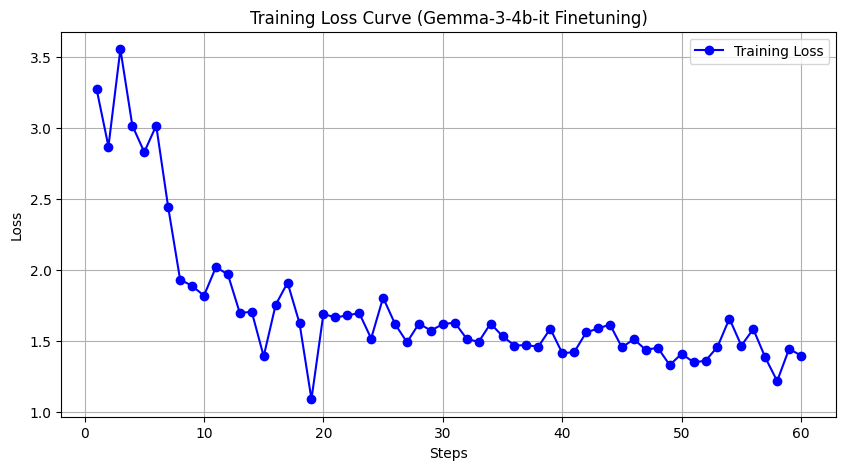

In [34]:
import matplotlib.pyplot as plt

# Extract training log history from the trainer
log_history = trainer.state.log_history

steps = []
losses = []

for log in log_history:
    if 'loss' in log and 'step' in log:
        steps.append(log['step'])
        losses.append(log['loss'])

# Plot the training loss
plt.figure(figsize=(10, 5))
plt.plot(steps, losses, marker='o', linestyle='-', color='b', label='Training Loss')
plt.title('Training Loss Curve (Gemma-3-4b-it Finetuning)')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()
plt.show()

#### 4. Practical Experiment
You can compare this customized Khmer financial/assistant model behavior with standard instruction datasets (like the loaded Alpaca set) to observe the divergence in behavioral format and language capability.